This project develops an AI-based clothing classifier system using MobileNet V2 transfer learning to classify clothing images into 5 categories viz: (T-shirts, shirts, jeans, dresses and short). Evaluation of the model was done using the followeing metrics: accuracy, training and validation loss curves, a confusion matrix, precision, specificity and recall scores.

In [ ]:
# 1. Import Libraries
import time
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import random

from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# Reproducibility (to prevent randomisation of results)
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.21.0
NumPy version: 2.1.3


In [ ]:
# 2. Download dataset from kaggle

import kagglehub

# Download latest version
path = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fashion-product-images-small' dataset.
Path to dataset files: /kaggle/input/fashion-product-images-small


In [ ]:
# 3. Load dataset

import os
import pandas as pd
from PIL import Image
import numpy as np

# Use the path returned by kagglehub in the previous step
dataset_dir = path
csv_path = os.path.join(dataset_dir, "styles.csv")
images_dir = os.path.join(dataset_dir, "images")

# Five clothing categories
class_names = ["Tshirts", "Shirts", "Jeans", "Dresses", "Shorts"]

# Load metadata using pandas, skipping bad rows if any exist
df = pd.read_csv(csv_path, on_bad_lines='skip')
print("Metadata loaded:", len(df), "rows")

# Filter rows for target categories and take up to 500 from each
selected_dfs = []
for category in class_names:
    category_df = df[df["articleType"] == category].head(500)
    print(category, ":", len(category_df), "images")
    selected_dfs.append(category_df)

# Combine and keep track of selected items
small_df = pd.concat(selected_dfs, ignore_index=True)
print("Total selected metadata rows:", len(small_df))

Metadata loaded: 44424 rows
Tshirts : 500 images
Shirts : 500 images
Jeans : 500 images
Dresses : 464 images
Shorts : 500 images
Total selected metadata rows: 2464


In [ ]:
# 4. prepare the images

X = []
y = []

# Convert category names into numeric labels
label_numbers = {
    name: number for number, name in enumerate(class_names)
}

for idx, row in small_df.iterrows():
    image_id = int(row["id"])
    image_path = os.path.join(images_dir, f"{image_id}.jpg")

    # Only process if the image file exists
    if os.path.exists(image_path):
        try:
            with Image.open(image_path) as img:
                image = img.convert("RGB")
                image = image.resize((160, 160))
                X.append(np.array(image))
                y.append(label_numbers[row["articleType"]])
        except Exception as e:
            # Handle corrupt images if any
            continue

X = np.array(X, dtype=np.uint8)
y = np.array(y, dtype=np.int32)

print("Image array:", X.shape)
print("Label array:", y.shape)

Image array: (2462, 160, 160, 3)
Label array: (2462,)


In [ ]:
# 5. split the dataset into training and testing sets


from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))

Training images: 1969
Testing images: 493


Class Distribution
---------------------------------------------
Tshirts         Training:  400 | Testing:  100
Shirts          Training:  399 | Testing:  100
Jeans           Training:  399 | Testing:  100
Dresses         Training:  371 | Testing:   93
Shorts          Training:  400 | Testing:  100


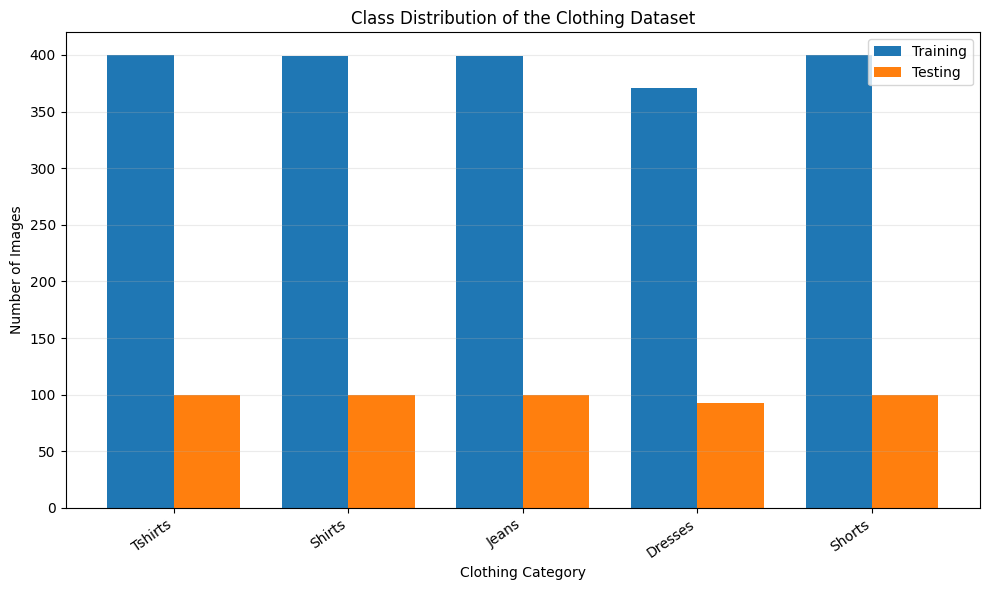

In [ ]:
# 6. Show the data class distribution (including the training and testing sets)

# Count images in each class
train_counts = Counter(y_train)
test_counts = Counter(y_test)

classes = class_names
training_values = [
    train_counts.get(i, 0) for i in range(len(classes))
]
testing_values = [
    test_counts.get(i, 0) for i in range(len(classes))
]

# Print the class distribution
print("Class Distribution")
print("-" * 45)

for i, category in enumerate(classes):
    print(
        f"{category:<15} "
        f"Training: {training_values[i]:4d} | "
        f"Testing: {testing_values[i]:4d}"
    )

# Plot the distribution
x = np.arange(len(classes))
width = 0.38

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    training_values,
    width,
    label="Training"
)

plt.bar(
    x + width / 2,
    testing_values,
    width,
    label="Testing"
)

plt.xticks(x, classes, rotation=35, ha="right")
plt.xlabel("Clothing Category")
plt.ylabel("Number of Images")
plt.title("Class Distribution of the Clothing Dataset")
plt.legend()
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


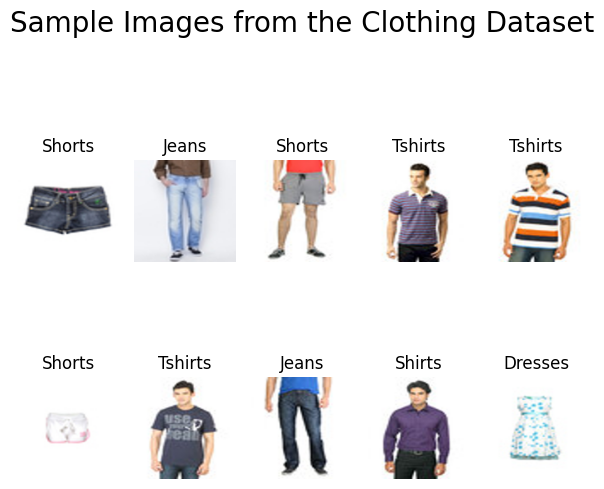

In [ ]:

# 7. Display 10 random training images
np.random.seed(42)
sample_indices = np.random.choice(
    len(X_train),
    size=min(10, len(X_train)),
    replace=False
)

plt.figure(figsize=(6, 6))

for position, index in enumerate(sample_indices):
    plt.subplot(2, 5, position + 1)

    # Display the image
    plt.imshow(X_train[index].astype("uint8"))

    # Display its actual category
    label = class_names[int(y_train[index])]
    plt.title(label)
    plt.axis("off")

plt.suptitle("Sample Images from the Clothing Dataset", fontsize=20)
plt.tight_layout()
plt.savefig("sample_clothing_images.png", dpi=300, bbox_inches="tight")
plt.show()


I decided to use MobileNetV2 CNN pre-trained on ImageNet for feature extraction

In [ ]:
# 8.  Build the model using MobileNetV2

# Load the pretrained model
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(160, 160, 3)
)

# Freeze the pretrained layers initially
base_model.trainable = False

# Build our clothing classifier
model = models.Sequential([
    layers.Input(shape=(160, 160, 3)),

    # Convert pixels from 0-255 to -1 to 1
    layers.Rescaling(1.0 / 127.5, offset=-1),

    base_model,

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(5, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_5 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# 9. Train the Model


# Prepare efficient training batches
train_data = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_data = train_data.map(
    lambda x, y: (tf.cast(x, tf.float32), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

train_data = train_data.shuffle(1000).batch(32).prefetch(
    tf.data.AUTOTUNE
)

test_data = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

test_data = test_data.map(
    lambda x, y: (tf.cast(x, tf.float32), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

test_data = test_data.batch(32).prefetch(tf.data.AUTOTUNE)

# Train for up to five epochs
history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=5
)

Epoch 1/5
62/62 ━━━━━━━━━━━━━━━━━━━━ 54s 796ms/step - accuracy: 0.7120 - loss: 0.7852 - val_accuracy: 0.9128 - val_loss: 0.3012
Epoch 2/5
62/62 ━━━━━━━━━━━━━━━━━━━━ 89s 918ms/step - accuracy: 0.9299 - loss: 0.2204 - val_accuracy: 0.9371 - val_loss: 0.1955
Epoch 3/5
62/62 ━━━━━━━━━━━━━━━━━━━━ 73s 760ms/step - accuracy: 0.9462 - loss: 0.1633 - val_accuracy: 0.9412 - val_loss: 0.1793
Epoch 4/5
62/62 ━━━━━━━━━━━━━━━━━━━━ 83s 789ms/step - accuracy: 0.9639 - loss: 0.1203 - val_accuracy: 0.9513 - val_loss: 0.1475
Epoch 5/5
62/62 ━━━━━━━━━━━━━━━━━━━━ 64s 1s/step - accuracy: 0.9685 - loss: 0.1033 - val_accuracy: 0.9615 - val_loss: 0.1308


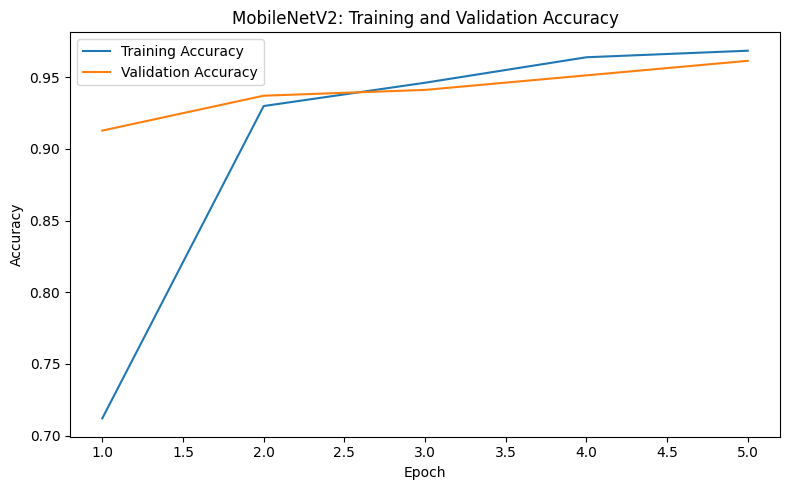

In [ ]:
# 9. Plot training and validation accuracy


train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

epochs = range(1, len(train_accuracy) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, train_accuracy,
         label="Training Accuracy")

plt.plot(epochs, val_accuracy,
         label="Validation Accuracy")

plt.title("MobileNetV2: Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


plt.tight_layout()
plt.show()

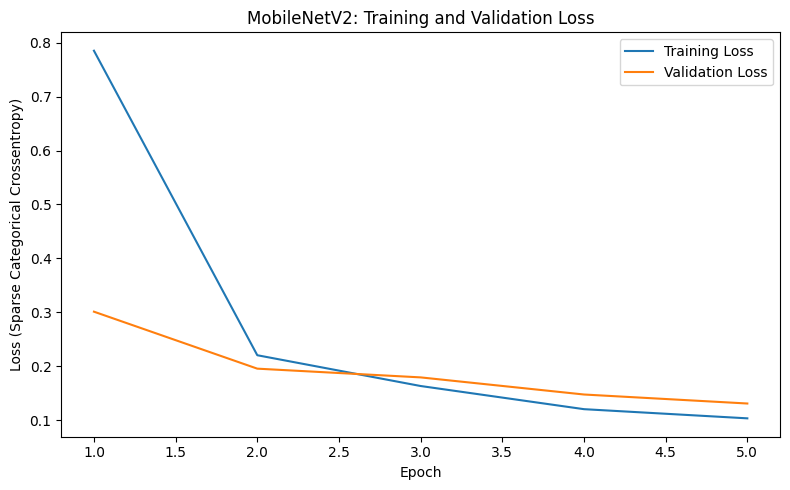

In [ ]:
# 10. plot training and validation loss


train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = range(1, len(train_loss) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, train_loss,
         label="Training Loss")

plt.plot(epochs, val_loss,
         label="Validation Loss")

plt.title("MobileNetV2: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (Sparse Categorical Crossentropy)")
plt.legend()


plt.tight_layout()

plt.show()

In [ ]:
# 11. Evaluate and save the Model

# Evaluate the model using the prepared test dataset
test_loss, test_acc = model.evaluate(test_data, verbose=2)

print(f"\nTest accuracy: {test_acc * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")

# Save the trained model
model.save("clothing_classifier.keras")

16/16 - 9s - 577ms/step - accuracy: 0.9615 - loss: 0.1308

Test accuracy: 96.15%
Test loss: 0.1308


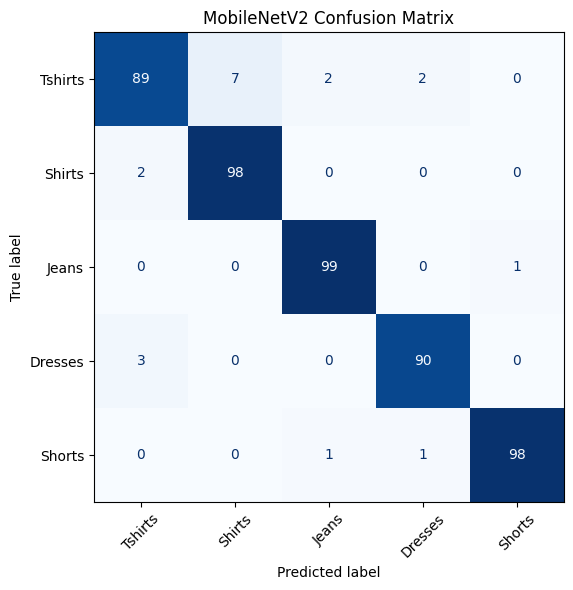

In [ ]:
# 12.  Generate confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load the correct saved model
model = tf.keras.models.load_model("clothing_classifier.keras")

# Generate predictions on the correct test dataset
y_true = np.concatenate([
    labels.numpy() for _, labels in test_data
])

probabilities = model.predict(test_data, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

# Calculate the confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(6, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("MobileNetV2 Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# 13. Get actual labels and model predictions
from IPython.display import display as ipy_display

# Ensure the correct test_data dataset variable is used
y_true = np.concatenate([
    labels.numpy() for _, labels in test_data
])

y_prob = model.predict(test_data, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Calculate macro-averaged metrics
precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

sensitivity = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

# Calculate specificity for each class
cm = confusion_matrix(
    y_true, y_pred,
    labels=np.arange(len(class_names))
)

specificity_values = []

for i in range(len(class_names)):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - tp - fn - fp

    specificity_values.append(
        tn / (tn + fp) if (tn + fp) > 0 else 0
    )

specificity = np.mean(specificity_values)

# Display results
results = pd.DataFrame({
    "Metric": [
        "Precision",
        "Sensitivity (Recall)",
        "F1-score",
        "Specificity"
    ],
    "Score": [
        precision,
        sensitivity,
        f1,
        specificity
    ]
})

results["Score (%)"] = (results["Score"] * 100).round(2)

ipy_display(results)

,Metric,Score,Score (%)
0,Precision,0.961674,96.17
1,Sensitivity (Recall),0.961548,96.15
2,F1-score,0.961298,96.13
3,Specificity,0.990358,99.04


In [ ]:
# 14. Download the trained model

from google.colab import files

files.download("clothing_classifier.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>